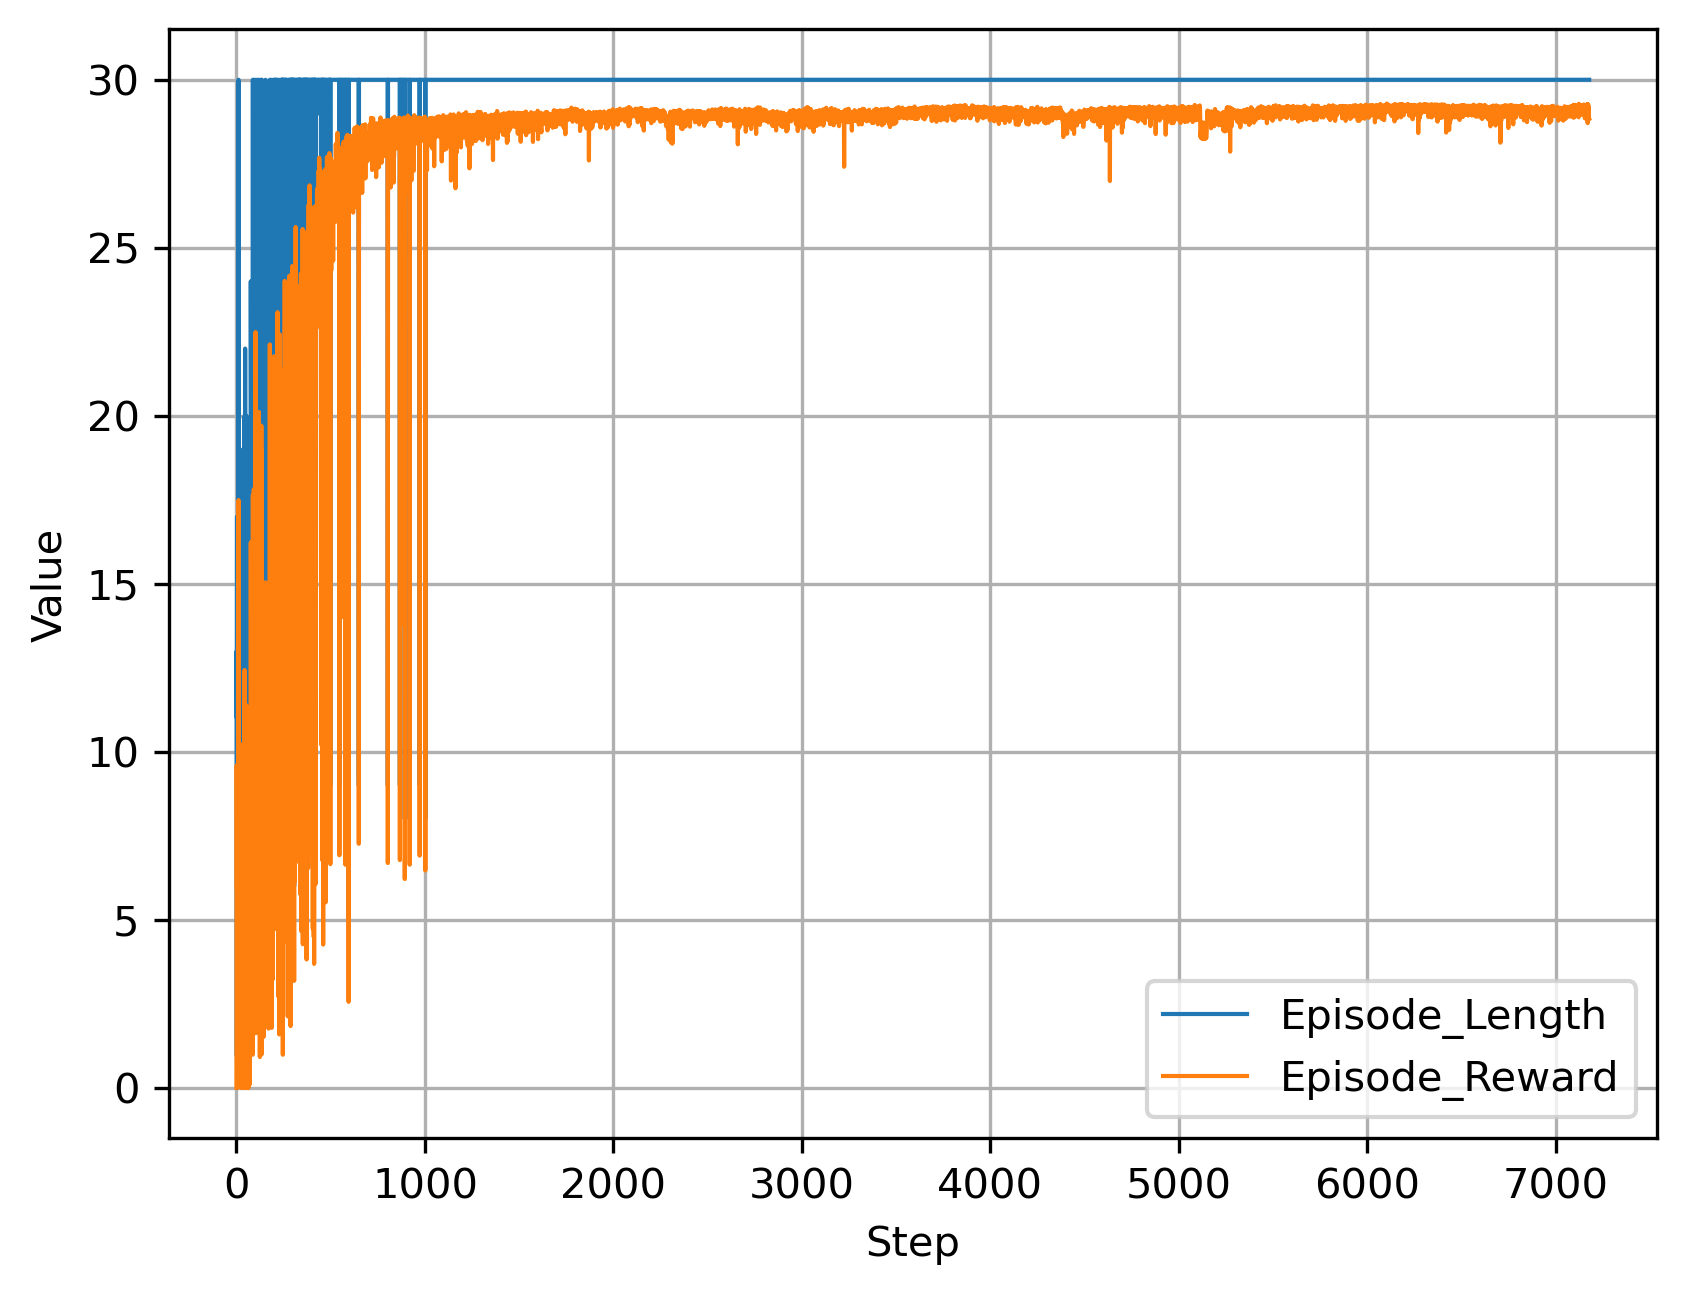

In [6]:
import os
import torch
import matplotlib.pyplot as plt
from torch.utils.tensorboard import SummaryWriter
from tensorboard.backend.event_processing import event_accumulator

def load_and_plot_tensorboard(run_folder, tags=None, semilogy=False):
    """
    Loads TensorBoard events from the specified run folder and plots the data.

    Args:
        run_folder (str): Path to the run folder containing TensorBoard event files.
        tags (list of str, optional): List of tags (e.g., 'loss', 'accuracy') to plot.
                                      If None, all scalar tags will be plotted.
    """
    # Create an EventAccumulator to load data from TensorBoard logs
    event_acc = event_accumulator.EventAccumulator(run_folder)
    event_acc.Reload()

    # If no specific tags are provided, use all available scalar tags
    if tags is None:
        tags = event_acc.Tags()['scalars']
    
    for tag in tags:
        # Retrieve scalar events for each tag
        scalar_events = event_acc.Scalars(tag)
        
        # Extract the steps and values
        steps = [e.step for e in scalar_events]
        values = [e.value for e in scalar_events]

        # Plot the data using Matplotlib
        if semilogy:
            plt.semilogy(steps, values, label=tag.split('/', 1)[-1], lw=1)
        else:
            plt.plot(steps, values, label=tag.split('/', 1)[-1], lw=1)

    # Add labels, title, and legend to the plot
    plt.xlabel('Step')
    plt.ylabel('Value')
    #plt.title(f'TensorBoard Scalars from {run_folder}')
    plt.legend()
    plt.grid(True)
    plt.show()

# Example usage:
run_folder = "runs/20241217-185649/"  # Replace with the path to your run folder
tags_to_plot = ['Performance/Episode_Length', 'Performance/Episode_Reward']  # You can specify the tags you want to plot

plt.figure(dpi=300)
# Plot the data
load_and_plot_tensorboard(run_folder, tags=tags_to_plot)


In [ ]:
# Example usage:
run_folder = "runs/20241217-185649/"  # Replace with the path to your run folder
tags_to_plot = ['Performance/Episode_Length']  # You can specify the tags you want to plot

plt.figure(dpi=300)
# Plot the data
load_and_plot_tensorboard(run_folder, tags=tags_to_plot)